<a href="https://colab.research.google.com/github/maqsood1842/Brain-Tumor-Classification/blob/main/notebooks/BrainTumor_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brain Tumor Classification (MobileNetV2)
**Before running:** Runtime > Change runtime type > **T4 GPU**, then Run all (or run cell by cell).

### MNIST Test Dataset (`mnist_test.csv`)

**Purpose of the File:**

* **What it is:** This file contains a subset of the famous **MNIST (Modified National Institute of Standards and Technology)** database. It consists of handwritten digits from 0 to 9.
* **Standard Testing Set:** This specific file serves as a **test dataset** (typically containing 10,000 samples) used to evaluate the performance and accuracy of trained machine learning models, particularly image classification algorithms.
* **Data Format:**
  * Each row represents a single 28x28 pixel grayscale image of a handwritten digit.
  * The first column contains the **label** (the actual digit, from 0 to 9).
  * The remaining 784 columns (from 2nd to 785th) contain the **pixel values** (ranging from 0 to 255) representing the 28x28 image unrolled into a single row.

## Step 1: Mount Drive and set paths

In [14]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, numpy as np, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

PROJECT = '/content/drive/MyDrive/BrainTumorProject'
TRAIN_DIR = f'{PROJECT}/dataset/Training'
TEST_DIR = f'{PROJECT}/dataset/Testing'
MODEL_DIR = f'{PROJECT}/model'
os.makedirs(MODEL_DIR, exist_ok=True)

print('TF', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
print(os.path.exists(TRAIN_DIR), os.path.exists(TEST_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TF 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
True True


## Step 2: Load data (224x224 RGB, 80/20 train/validation split, test set untouched)

Found 5601 files belonging to 4 classes.
Using 4481 files for training.
Found 5601 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


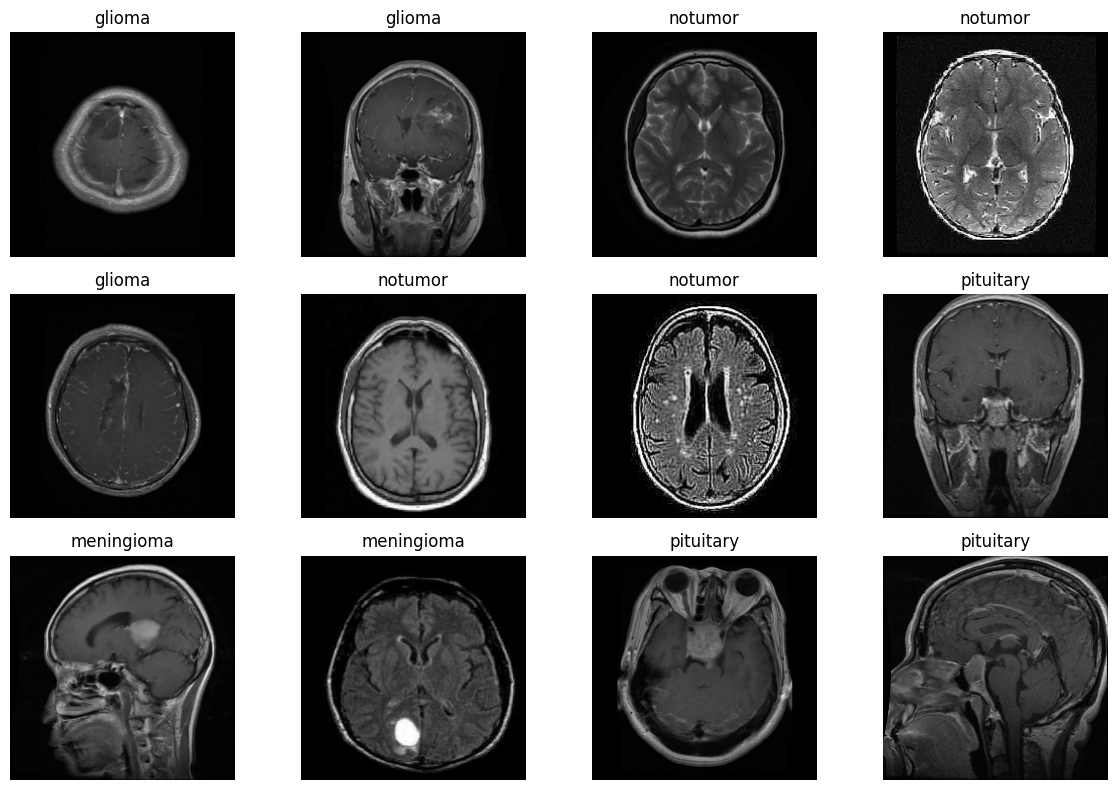

In [15]:
IMG_SIZE = (224, 224)
BATCH = 32
SEED = 42

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset='training', seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH, color_mode='rgb', label_mode='int')
val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset='validation', seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH, color_mode='rgb', label_mode='int')
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH, color_mode='rgb',
    label_mode='int', shuffle=False)

class_names = train_ds.class_names
print('Classes:', class_names)
with open(f'{MODEL_DIR}/class_names.json', 'w') as f:
    json.dump(class_names, f)

# Visualize samples
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]])
        plt.axis('off')
plt.tight_layout(); plt.show()

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

## Step 3: Build model (MobileNetV2 transfer learning)

In [16]:
augment = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name='augmentation')

base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')
base_model.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Step 4: Train, phase 1 (frozen base)

In [17]:
callbacks = [
    keras.callbacks.ModelCheckpoint(f'{MODEL_DIR}/best_model.keras', monitor='val_accuracy',
                                    save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1),
]

history1 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks)

Epoch 1/10
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.5735 - loss: 1.0291
Epoch 1: val_accuracy improved from None to 0.85893, saving model to /content/drive/MyDrive/BrainTumorProject/model/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/BrainTumorProject/model/best_model.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - accuracy: 0.7021 - loss: 0.7422 - val_accuracy: 0.8589 - val_loss: 0.4053 - learning_rate: 0.0010
Epoch 2/10
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.8195 - loss: 0.4679
Epoch 2: val_accuracy did not improve from 0.85893
141/141 ━━━━━━━━━━━━━━━━━━━━ 14s 97ms/step - accuracy: 0.8331 - loss: 0.4370 - val_accuracy: 0.8580 - val_loss: 0.3771 - learning_rate: 0.0010
Epoch 3/10
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.8445 - loss: 0.3992
Epoch 3: val_accuracy improved from 0.85893 to 0.88750, saving model to /content/drive/MyDrive/BrainTumorProject/model/best_model.keras

Epoch 3: finished saving model t

## Step 5: Fine-tune (unfreeze last 30 layers, low learning rate)

In [18]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history2 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks)

Epoch 1/10
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.7843 - loss: 0.6258
Epoch 1: val_accuracy did not improve from 0.90536
141/141 ━━━━━━━━━━━━━━━━━━━━ 26s 117ms/step - accuracy: 0.8159 - loss: 0.5188 - val_accuracy: 0.8973 - val_loss: 0.3165 - learning_rate: 1.0000e-05
Epoch 2/10
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.8407 - loss: 0.4158
Epoch 2: val_accuracy did not improve from 0.90536

Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
141/141 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - accuracy: 0.8563 - loss: 0.3861 - val_accuracy: 0.8893 - val_loss: 0.3344 - learning_rate: 1.0000e-05
Epoch 3/10
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.8716 - loss: 0.3401
Epoch 3: val_accuracy did not improve from 0.90536
141/141 ━━━━━━━━━━━━━━━━━━━━ 15s 107ms/step - accuracy: 0.8766 - loss: 0.3336 - val_accuracy: 0.8893 - val_loss: 0.3284 - learning_rate: 5.0000e-06
Epoch 4/10
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 

## Step 6: Training curves

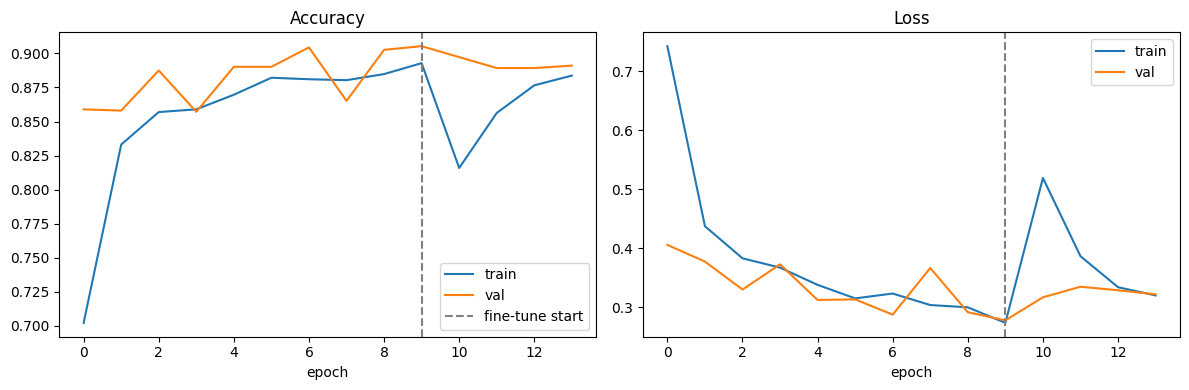

In [19]:
def merge(k):
    return history1.history[k] + history2.history[k]

acc, val_acc, loss, val_loss = merge('accuracy'), merge('val_accuracy'), merge('loss'), merge('val_loss')
split = len(history1.history['accuracy'])

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label='train'); plt.plot(val_acc, label='val')
plt.axvline(split - 1, color='gray', ls='--', label='fine-tune start')
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(loss, label='train'); plt.plot(val_loss, label='val')
plt.axvline(split - 1, color='gray', ls='--')
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/training_curves.png', dpi=150)
plt.show()

## Step 7: Evaluate on the untouched test set

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step - accuracy: 0.8106 - loss: 0.6986
Test accuracy: 0.8106  |  Test loss: 0.6986
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step
              precision    recall  f1-score   support

      glioma     0.9345    0.6775    0.7855       400
  meningioma     0.7763    0.5900    0.6705       400
     notumor     0.8358    0.9800    0.9022       400
   pituitary     0.7412    0.9950    0.8495       400

    accuracy                         0.8106      1600
   macro avg     0.8219    0.8106    0.8019      1600
weighted avg     0.8219    0.8106    0.8019      1600



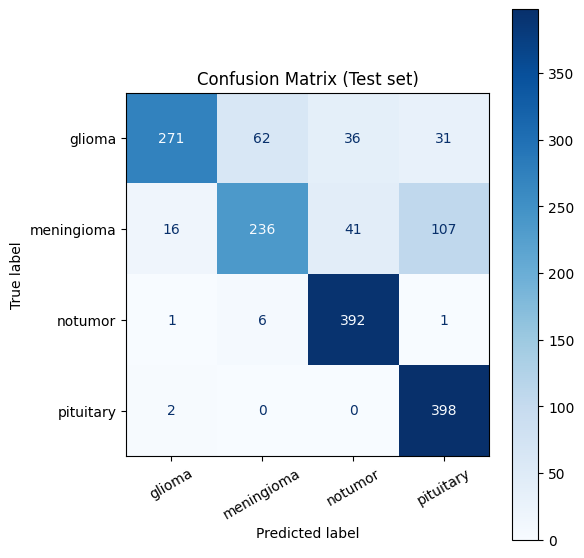

In [20]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

test_loss, test_acc = model.evaluate(test_ds)
print(f'Test accuracy: {test_acc:.4f}  |  Test loss: {test_loss:.4f}')

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', xticks_rotation=30)
plt.title('Confusion Matrix (Test set)')
plt.tight_layout()
plt.savefig(f'{MODEL_DIR}/confusion_matrix.png', dpi=150)
plt.show()

## Step 8: Save the final model to Drive

In [21]:
model.save(f'{MODEL_DIR}/brain_tumor_model.keras')
print('Saved:', os.listdir(MODEL_DIR))

# Sanity check: reload and predict one test image
loaded = keras.models.load_model(f'{MODEL_DIR}/brain_tumor_model.keras')
for images, labels in test_ds.take(1):
    p = loaded.predict(images[:1])
    print('True:', class_names[labels[0]], '| Predicted:', class_names[int(np.argmax(p))], f'({p.max():.2%})')

Saved: ['class_names.json', 'best_model.keras', 'training_curves.png', 'confusion_matrix.png', 'brain_tumor_model.keras']
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
True: glioma | Predicted: notumor (48.23%)


In [22]:
import os
import shutil
from google.colab import drive, files

# Ensure Drive is mounted
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

# Source path inside Google Drive
drive_path = "/content/drive/MyDrive/BrainTumorProject/model/brain_tumor_model.keras"

# Local download destination
local_path = "/content/brain_tumor_model.keras"

if os.path.exists(drive_path):
    # Copy and download
    shutil.copy(drive_path, local_path)
    files.download(local_path)
else:
    print(f"Error: The model file was not found at {drive_path}. Please make sure you have run the cell to save the model first.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>